<center><h1> ETI195 - etica para Ciencia de Datos y Estadistica </h1><center>
<center><h2> Taller Sumativo 4: Human Rights approach to data y privacidad <h2><center>


**Integrantes del grupo:**

1. Sergio Andres Hernandez Salgado
2. Marco Antonio Ramirez Gaete
3. Reinaldo Rodrigo Oliva Morales
4. Juan Tomas Jose Lepivil Vigueras

**Dataset:** CASEN 2024 preprocesado. Variable objetivo: `pobreza_multi`.

# Human Rights approach to data y privacidad

>Contexto

En estos talleres, estamos trabajando con datos que pueden influir en vidas de personas. Esto implica una responsabilidad etica especial, las personas o grupos de personas detras pueden verse impactadas tanto de forma positiva como negativa con las decisiones basadas en datos que tomemos. Antes de hacer cualquier analisis, debes preguntarte como tratarias esos datos si fueras quien los recolecta, y como podrias compartirlos si resguardar la identidad de los involucrados fuese prioridad.

>Objetivos

El objetivo de este taller es diseñar un marco de recoleccion de datos basado en derechos humanos sobre los problemas que han estado tratando, asi como identificar si cumplen o no con el marco regulatorio chileno, aplicar DataSynthesizer para generar una version sintetica del dataset, generar visualizaciones y proponer mejoras al dataset desde la perspectiva del activismo de datos.

> # instrucciones generales

Esta es la parte IV del proyecto, consideren utilizar sus resultados anteriores y reciclar el codigo de los talleres previos. El taller puede aplicarse sobre cualquiera de los tres datasets del proyecto; trabajen con el mismo dataset que eligieron en los talleres anteriores y respondan cada pregunta en funcion de ese contexto.

Si trabajan con CIRI, notaran que sus datos son indicadores agregados por pais y año, por lo que no contienen informacion personal que deba protegerse. Aun asi, la idea es que aprendan a utilizar las herramientas de privacidad diferencial y generacion de datos sinteticos, ya que el procedimiento es el mismo independiente del dataset, y que reflexionen sobre que ocurriria si estos datos tuvieran un mayor nivel de detalle, por ejemplo, registros individuales de victimas, como se plantea en la pregunta 6.

## `Temas formales`

Modalidad: Grupos de 3 personas.

Fecha de entrega: 20 de noviembre.

Formato de entrega: El trabajo debe entregarse a traves de Canvas, tanto en formato Jupyter ejecutable (.ipynb) como en formato PDF.

Formalidades de las respuestas:
- Citas: APA 7.
- Se espera buena ortografia y redaccion, con respuestas en tono academico.
- No respondan con simples "si" o "no", consideren argumentar sus respuestas y justificar con bibliografia si lo estiman necesario.

## `Integridad academica y uso de IA`

El uso de asistentes de IA sigue los lineamientos de integridad academica del curso, con las siguientes excepciones:

- Pueden usar IA para consultar por bugs y entender mejor el codigo.
- Pueden usar IA para generar las representaciones visuales que estimen convenientes.

Si tienen dudas sobre el uso de IA o la citacion de codigo externo, no duden en preguntar. Pueden usar libremente los codigos de los talleres formativos. <3

## `Recomendaciones`

- Asistan a los talleres formativos, revisen los ejemplos de codigo y consulten sus dudas con sus ayudantes :D.



In [1]:
# importacion de librerias
# Si no tienen DataSynthesizer instalado, en una terminal (sin "!") ejecuten:
#   python -m pip install git+https://github.com/DataResponsibly/DataSynthesizer.git
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from DataSynthesizer.DataDescriber import DataDescriber
from DataSynthesizer.DataGenerator import DataGenerator
from DataSynthesizer.ModelInspector import ModelInspector, kl_test, ks_test
from DataSynthesizer.lib.utils import read_json_file, display_bayesian_network

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 20)


### _`Importantes: A lo largo del notebook habran preguntas guias para los analisis de resultados, operacion de codigo y otros, se espera que las respondan o hagan alusion a ellas en sus respuestas `_

<br><br>
**`Pregunta (1`) Describa el objetivo y las variables del dataset desde una perspectiva distinta**.

¿A simple vista, consideras que alguna de estas variables podria ser mal utilizada, perjudicando a alguna comunidad?

¿Por que crees que se consideran esas variables y no otras para el objetivo del dataset?

<br><br>


**Respuesta pregunta 1**

**El objetivo visto desde otro lado.** Normalmente vemos la CASEN como una herramienta del Estado para medir la pobreza y decidir a quien ayudar. En nuestros talleres la usamos para predecir si una persona vive en un hogar en pobreza multidimensional (`pobreza_multi`). Pero, desde el lado de las personas encuestadas, la CASEN es otra cosa: **un registro muy detallado de su vida privada**. Dice cuantas personas viven en su casa, en que estado estan los muros y el piso, si tienen trabajo o contrato, a que sistema de salud pertenecen, si tienen alguna discapacidad, si son indigenas o migrantes, e incluso su orientacion sexual. Las personas entregan esta informacion confiando en que se usara para mejorar sus condiciones, no para clasificarlas o vigilarlas.

Las variables de nuestra base se pueden agrupar asi:

| Grupo | Variables | Que describen |
|---|---|---|
| Hogar y vivienda | `tot_per_h`, `p9`, `v1`–`v29b`, `ind_hacina` | Tamaño del hogar, materiales y estado de la vivienda, hacinamiento, servicios |
| Entorno | `p2`, `p3`, `p4`, `area` | Estado del barrio (basura, vandalismo) y zona urbana o rural |
| Bienes | `r14`, `r17a`–`r17c` | Vehiculo e internet |
| Persona | `edad`, `sexo`, `e1`, `e9depen`, `o1`, `o19`, `o31`, `s13`, `h7e`, `h7f` | Educacion, trabajo, prevision, salud y discapacidad |
| Identidad | `r3`, `r1a`, `os1`, `trans` | Pueblo indigena, nacionalidad, orientacion sexual e identidad trans |

**¿Alguna variable podria usarse mal?** Si. Las mas delicadas son las de identidad (`r3`, `r1a`, `os1`, `trans`), las de discapacidad (`h7e`, `h7f`) y las del barrio (`p2`, `p3`, `p4`). La tabla de abajo muestra que el porcentaje de pobreza cambia bastante entre grupos. Esa informacion sirve para detectar desigualdades, pero tambien podria usarse para estigmatizar ("los migrantes son pobres"), para negar servicios o para que un modelo trate peor a ciertos grupos. Esto ya lo vimos en el Taller 3: BETO le bajaba la confianza a un mensaje positivo solo por decir "inmigrante" o "mapuche", y el Random Forest se equivocaba distinto segun el grupo. Ademas, cuando se combinan varias de estas variables (por ejemplo, persona trans, indigena, de zona rural y de cierta edad), los grupos se vuelven tan pequeños que alguien podria ser **reidentificado**.

**¿Por que estas variables y no otras?** Porque siguen la metodologia oficial de pobreza multidimensional del Ministerio de Desarrollo Social y Familia, que mide carencias en educacion, salud, trabajo y seguridad social, vivienda y entorno, y redes y cohesion social. Las variables de identidad se incluyen para poder **desagregar**, es decir, ver si la pobreza afecta mas a ciertos grupos, como piden los Objetivos de Desarrollo Sostenible ("no dejar a nadie atras"). Lo que no aparece tambien dice algo: no estan los ingresos (en nuestra version), el territorio especifico ni la opinion de las propias personas sobre que significa para ellas ser pobres. La seleccion refleja **como el Estado define la pobreza**, no necesariamente como la viven las comunidades.

In [ ]:
# Usamos la misma base limpia de los talleres anteriores
df = pd.read_csv("data/casen_2024.csv")
print("Filas y columnas:", df.shape)
print("Columnas con datos faltantes:", int((df.isnull().sum() > 0).sum()))

# Correccion de tipos (igual que en los talleres 1, 2 y 3): estas columnas son codigos, no cantidades
codigos = ["p2", "p3", "p4", "ind_hacina", "o1", "h7e", "h7f",
           "r14", "r17a", "r17b", "r17c", "v3", "v5", "v23"]
df[codigos] = df[codigos].astype("string")
df["pobreza_multi"].value_counts(normalize=True).round(3)

Filas y columnas: (212471, 42)
Columnas con datos faltantes: 0


pobreza_multi
No pobre    0.824
Pobre       0.176
Name: proportion, dtype: float64

In [ ]:
# Variables que podrian usarse para perjudicar a una comunidad (pregunta 1):
# cuantas personas hay en cada grupo y que porcentaje esta en pobreza multidimensional
sensibles = {"r3": "Pueblo indigena", "r1a": "Nacionalidad", "os1": "Orientacion sexual",
             "trans": "Identidad trans", "h7e": "Dificultad cuidado personal", "sexo": "Sexo", "area": "Zona"}
filas = []
for var, nombre in sensibles.items():
    for grupo, sub in df.groupby(var):
        filas.append({"variable": f"{var} ({nombre})", "grupo": grupo, "personas": len(sub),
                      "% en pobreza": round(100 * (sub["pobreza_multi"] == "Pobre").mean(), 1)})
pd.DataFrame(filas)

,variable,grupo,personas,% en pobreza
0,r3 (Pueblo indígena),Indígena,29645,23.8
1,r3 (Pueblo indígena),No indígena,182826,16.6
2,r1a (Nacionalidad),Chile,197884,16.8
3,r1a (Nacionalidad),Chile y otro país,2282,16.7
4,r1a (Nacionalidad),Extranjero,12305,32.1
5,os1 (Orientación sexual),Bisexual,1131,13.4
6,os1 (Orientación sexual),Gay/Lesbiana,1145,13.8
7,os1 (Orientación sexual),Heterosexual,207339,17.6
8,os1 (Orientación sexual),No sabe,405,26.4
9,os1 (Orientación sexual),Otra,174,19.0



### `2: Exploracion de datos y limpieza.`

Basta con que lo hayan realizado en los talleres anteriores, solo consideren usar el dataset limpio para lo que viene.

La limpieza y el tratamiento de datos ya se hicieron en los talleres 1 y 2 (la base no tiene datos faltantes). La carga de la base limpia y la correccion de tipos estan en las celdas de codigo de la pregunta 1.

### `3: Analisis de principios.`

**`Pregunta (3)` Identifique si el dataset seleccionado cumple con los principios de Human Rights approach to data. Si cumple, explique por que cumple. Si no cumple, proponga un nuevo marco de recoleccion o tratamiento que si cumpla.**

Recuerda apoyarte en bibliografia externa, puedes sugerir marcos y metodos de tratamiento de datos utilizados en casos similares. Argumenta solidamente tu eleccion.



**Respuesta pregunta 3**

Usamos los seis principios del enfoque de derechos humanos para los datos de la Oficina del Alto Comisionado de la ONU para los Derechos Humanos (OHCHR, 2018): **participacion, desagregacion, autoidentificacion, transparencia, privacidad y rendicion de cuentas**.

| Principio | ¿Cumple la CASEN? | Por que |
|---|---|---|
| Participacion |  No | Las preguntas y la definicion de pobreza las diseñan equipos tecnicos y paneles de expertos. Las personas y comunidades solo participan como informantes. |
| Desagregacion |  Si, en general | Permite separar por sexo, edad, pueblo indigena, nacionalidad, zona, orientacion sexual, identidad trans y discapacidad. El problema es que algunos grupos tienen muy pocos casos para obtener resultados confiables. |
| Autoidentificacion |  Parcial | Pertenencia indigena, orientacion sexual e identidad de genero se preguntan como autoidentificacion. Pero en muchos modulos una sola persona del hogar responde por todos, asi que la identidad de los demas la declara otra persona. |
| Transparencia |  Si, en general | Se publican la metodologia, los cuestionarios, los libros de codigos y las bases. Sin embargo, todo esta en un lenguaje tecnico dificil de entender para la poblacion. |
| Privacidad |  Parcial | La base publica no trae nombres ni direcciones. Aun asi, combinando variables hay personas con combinaciones unicas (lo medimos en la pregunta 5), y muchos datos son sensibles segun la ley chilena. |
| Rendicion de cuentas |  Parcial | Existe la Ley de Transparencia, pero no hay un mecanismo claro para que una persona sepa como se usaron sus datos o reclame si un uso la perjudica (por ejemplo, un modelo de focalizacion). |

**Conclusion:** la CASEN cumple solo en parte. Es fuerte en desagregacion y transparencia tecnica, pero debil en participacion y rendicion de cuentas.

**Propuesta de un marco que si cumpla:**

1. **Co-diseño con comunidades.** Antes de cada version, organizar mesas con organizaciones indigenas, de migrantes, de diversidad sexual y de personas con discapacidad para revisar que se pregunta, como se pregunta y para que se usaran los resultados. Al terminar, devolver los resultados en lenguaje simple.
2. **Autoidentificacion real.** Las preguntas sensibles (pueblo indigena, orientacion sexual, identidad de genero) deberian responderlas cada persona por si misma, con la opcion "prefiero no responder".
3. **Consentimiento informado y claro.** Explicar en palabras simples para que se usan los datos y que se puede dejar sin responder un modulo sensible sin perder nada.
4. **Acceso por niveles**, basado en el modelo de las "cinco seguridades" (*Five Safes*: proyectos, personas, entornos, datos y resultados seguros; Desai et al., 2016):
   - *Publico:* cifras agregadas y datos **sinteticos con privacidad diferencial**, como los de la pregunta 5.
   - *Investigacion:* microdatos anonimizados, con un acuerdo de uso firmado.
   - *Restringido:* datos con ubicacion o identificadores, solo dentro de un entorno seguro y para proyectos aprobados.
5. **No publicar grupos demasiado pequeños.** Cuando una combinacion tiene pocos casos, se agrupa o se suprime.
6. **Rendicion de cuentas.** Evaluar el impacto antes de usar los datos en modelos que decidan sobre personas, publicar esos usos y tener un canal donde reclamar.

<br><br>
### `4: Analisis regulatorio.`

**`Pregunta (4)` Proponga un metodo de recoleccion de este tipo de datos imaginando que fuese requerido para Chile. El metodo debe cumplir con el marco regulatorio chileno, considerando las politicas que entraron y entraran en vigencia.**

Al momento de explicar el metodo propuesto, recuerda hacer alusion a principios, temas y/o articulos especificos de la regulacion vigente o de discusiones academicas en torno a esta.

**Respuesta pregunta 4**

**Marco regulatorio chileno que aplica:**

- **Constitucion, art. 19 N° 4:** desde la Ley 21.096 (2018) reconoce la proteccion de los datos personales como un derecho.
- **Ley 19.628** sobre proteccion de la vida privada (1999): la ley vigente hoy.
- **Ley 21.719** (publicada el 13 de diciembre de 2024): modifica profundamente la Ley 19.628 y crea la **Agencia de Proteccion de Datos Personales**. Su vigencia original es el **1 de diciembre de 2026**. Sin embargo, el 17 de noviembre de 2026 el Congreso despacho un proyecto (boletin 18.623-07) que la **posterga al 15 de octubre de 2027** y amplia el consejo de la Agencia. Al momento de escribir, todavia falta su promulgacion y publicacion en el Diario Oficial (AZ, 2026; Eguiguren Abogados, 2026). En cualquier caso, nuestra propuesta se diseña para cumplir con la Ley 21.719, porque es la que regira.
- **Ley 17.374** (INE): establece el **secreto estadistico**.
- **Ley 20.285** de Transparencia: permite acceder a informacion publica, pero protege los datos personales.

**Punto clave:** casi todo lo que pregunta la CASEN es un **dato sensible**. La Ley 21.719 (art. 2, letra g) define asi los datos que revelan "el origen etnico o racial", "la situacion socioeconomica", los datos de salud, "la orientacion sexual" y "la identidad de genero". La regla general es que los datos sensibles solo se pueden tratar con **consentimiento expreso** (art. 16).

**Metodo de recoleccion propuesto** (imaginando que el Estado necesitara recolectar estos datos con ubicacion exacta del hogar, como plantea el escenario de la pregunta 6):

1. **Base legal clara.** Un organo publico puede tratar datos dentro de sus funciones sin consentimiento (art. 20), y la ley permite el tratamiento con fines estadisticos y de investigacion de interes publico (art. 16 quinquies). Aun asi, proponemos pedir **consentimiento expreso** para el modulo sensible (identidad, salud, ingresos), con la opcion de no responder. No es obligatorio en todos los casos, pero es coherente con el enfoque de derechos de la pregunta 3.
2. **Finalidad** (art. 3, letra b). Declarar desde el inicio que los datos son para estadistica y diseño de politicas sociales, y **prohibir otros usos**: fiscalizacion, control migratorio o cruces con otras bases para sancionar.
3. **Proporcionalidad** (art. 3, letra c). Preguntar solo lo necesario. La direccion exacta se usa para la logistica de la encuesta y luego se guarda aparte; para el analisis basta con la comuna o la manzana.
4. **Seudonimizacion** (art. 2, letra l). Separar los identificadores (nombre, RUT, direccion) de las respuestas, unirlos solo con un codigo y guardar la "llave" en otro lugar, con acceso restringido.
5. **Seguridad y confidencialidad** (art. 3, letras f y h). Cifrar los datos, registrar quien accede y exigir a encuestadores y analistas el deber de secreto, igual que el secreto estadistico de la Ley 17.374.
6. **Transparencia e informacion** (art. 3, letra g). Entregar en cada visita una hoja simple: quien trata los datos, para que, cuanto tiempo se guardan y como ejercer los derechos de acceso, rectificacion, supresion, oposicion y portabilidad.
7. **Publicacion anonimizada.** La ley exige anonimizar antes de publicar resultados obtenidos con fines estadisticos (art. 16 quinquies). La anonimizacion debe ser **irreversible** (art. 2, letra k). Por eso proponemos publicar cifras agregadas, suprimir los grupos pequeños y entregar **datos sinteticos con privacidad diferencial** como los que generamos en la pregunta 5.
8. **Supervision.** Designar un responsable de proteccion de datos en la institucion y someterse a la fiscalizacion de la Agencia de Proteccion de Datos Personales.

Una discusion importante es que la anonimizacion "irreversible" que pide la ley es dificil de garantizar con microdatos tan detallados: combinando pocas variables, una persona puede quedar sola en su grupo (Sweeney, 2002). Por eso la privacidad diferencial es util: no depende de adivinar que informacion adicional tendra un atacante (Dwork & Roth, 2014).

<br><br>
### `5: Privacidad diferencial.`

**`Pregunta (5)` Aplica las tecnicas de privacidad diferencial vistas para anonimizar el dataset y comenta los resultados.**

      - Selecciona a lo mas 7 variables para aplicar la tecnica. Mencionalas y justifica tu eleccion.
      - Obtenga la descripcion del dataset en alguno de los modos, justifique su eleccion. Guarde dicha descripcion en un archivo local
      (en formato JSON)
      - Genere los datos sinteticos usando DataGenerator
      - Aplique ModelInspector para comparar las distribuciones entre los datos originales y los datos sinteticos.

<br><br>

**Respuesta pregunta 5**

**Variables elegidas (7) y por que:**

| Variable | Que es | Por que la elegimos |
|---|---|---|
| `pobreza_multi` | Pobreza multidimensional | Es la variable objetivo de todo el proyecto. |
| `sexo` | Sexo | Permite ver brechas de genero. |
| `r3` | Pueblo indigena | Dato sensible (origen etnico), clave para ver desigualdades. |
| `r1a` | Nacionalidad | Dato sensible en la practica: poblacion migrante. |
| `area` | Urbano / rural | Muestra desigualdades territoriales. |
| `edad` | Edad | Cuasi-identificador: combinada con otras, ayuda a identificar personas. |
| `tot_per_h` | Personas en el hogar | La variable mas importante del Random Forest segun SHAP (Taller 3). |

Elegimos una mezcla de **atributos sensibles** (los que queremos proteger y a la vez analizar) y **cuasi-identificadores** (los que podrian usarse para reidentificar a alguien). Dejamos fuera `os1` y `trans` a proposito: son grupos muy pequeños, y la privacidad diferencial agrega tanto ruido a grupos chicos que su informacion se perderia. Ademas, son los grupos con mas riesgo de ser identificados, asi que no deberian publicarse a nivel individual.

In [ ]:
# Pregunta 5: seleccionamos 7 variables
variables = ["pobreza_multi", "sexo", "r3", "r1a", "area", "edad", "tot_per_h"]
df_dp = df[variables].copy()

# Guardamos este subconjunto como CSV porque DataDescriber lee el archivo
df_dp.to_csv("casen_7_variables.csv", index=False)

# ¿Que tan facil seria identificar a alguien con solo estas 7 variables?
# Contamos cuantas personas tienen una combinacion que nadie mas comparte (k = 1)
tam_grupo = df_dp.groupby(variables)[variables[0]].transform("size")
print(f"Combinaciones distintas: {df_dp.drop_duplicates().shape[0]:,}")
print(f"Personas con una combinacion unica (k=1): {(tam_grupo == 1).sum():,} "
      f"({(tam_grupo == 1).mean():.2%})")
print(f"Personas en grupos de menos de 5 (k<5): {(tam_grupo < 5).sum():,} ({(tam_grupo < 5).mean():.2%})")

Combinaciones distintas: 15,046
Personas con una combinación única (k=1): 4,694 (2.21%)
Personas en grupos de menos de 5 (k<5): 16,057 (7.56%)


Antes de generar datos sinteticos, medimos el riesgo de la base original. Con solo estas 7 variables, **4.694 personas (2,2 %) tienen una combinacion que nadie mas comparte**, y 16.057 (7,6 %) estan en grupos de menos de 5 personas. Si alguien conociera la edad, el sexo, la nacionalidad, la zona y el tamaño del hogar de un vecino, podria encontrarlo en la base y saber si es pobre o indigena. Por eso no basta con borrar nombres y direcciones (Sweeney, 2002).

**Modo elegido: correlacionado (*correlated attribute mode*).** DataSynthesizer tiene tres modos (Ping et al., 2017):

- **Aleatorio:** genera valores al azar dentro del tipo de dato. Protege mucho, pero no sirve para analizar nada.
- **Independiente:** copia la distribucion de cada variable por separado, con ruido. Se pierden las relaciones entre variables: por ejemplo, ya no se veria que la pobreza es mayor en zonas rurales.
- **Correlacionado:** aprende una **red bayesiana** que guarda las relaciones mas importantes entre variables y les agrega ruido de privacidad diferencial.

Elegimos el modo correlacionado porque lo que nos interesa (y lo que sirve para el activismo de la pregunta 7) son justamente las **relaciones** entre pobreza y grupos. Usamos **ε = 1**, un nivel intermedio: con ε mas bajo hay mas privacidad pero mas ruido, y con ε mas alto pasa lo contrario (Dwork & Roth, 2014). Usamos **k = 2**: cada variable puede depender de hasta dos variables. Mas padres capturan mas relaciones, pero reparten el ruido entre mas combinaciones.

In [ ]:
# Descripcion del dataset en modo correlacionado con privacidad diferencial
EPSILON = 1      # presupuesto de privacidad: menor = mas ruido y mas privacidad
K = 2            # maximo de "padres" de cada variable en la red bayesiana

es_categorica = {"pobreza_multi": True, "sexo": True, "r3": True, "r1a": True, "area": True,
                 "tot_per_h": True, "edad": False}
es_llave = {v: False for v in variables}   # ninguna variable identifica directamente a una persona

describer = DataDescriber(category_threshold=20)
describer.describe_dataset_in_correlated_attribute_mode(
    dataset_file="casen_7_variables.csv",
    epsilon=EPSILON,
    k=K,
    attribute_to_is_categorical=es_categorica,
    attribute_to_is_candidate_key=es_llave,
)

# Guardamos la descripcion en un archivo local en formato JSON
describer.save_dataset_description_to_file("descripcion_casen_dp.json")
print("\nDescripcion guardada en descripcion_casen_dp.json")

================ Constructing Bayesian Network (BN) ================
Adding ROOT sexo
Adding attribute area
Adding attribute edad
Adding attribute tot_per_h
Adding attribute pobreza_multi
Adding attribute r1a
Adding attribute r3
========================== BN constructed ==========================

Descripción guardada en descripcion_casen_dp.json


In [ ]:
# Red bayesiana aprendida: que variable depende de cuales
display_bayesian_network(describer.bayesian_network)

Constructed Bayesian network:
    area          has parents ['sexo'].
    edad          has parents ['area', 'sexo'].
    tot_per_h     has parents ['edad', 'sexo'].
    pobreza_multi has parents ['tot_per_h', 'area'].
    r1a           has parents ['pobreza_multi', 'edad'].
    r3            has parents ['edad', 'area'].


La red bayesiana muestra que relaciones decidio conservar el modelo. Por ejemplo, `pobreza_multi` depende del tamaño del hogar y de la zona, y la nacionalidad (`r1a`) depende de la pobreza y la edad. Ojo: **`r3` (pueblo indigena) quedo conectada solo con la edad y la zona, no con la pobreza.** Esto tendra consecuencias en la pregunta 7.

In [ ]:
# Generamos el dataset sintetico con el mismo numero de filas que el original
n = len(df_dp)
generator = DataGenerator()
generator.generate_dataset_in_correlated_attribute_mode(n, "descripcion_casen_dp.json")
generator.save_synthetic_data("casen_sintetico.csv")

sintetico = pd.read_csv("casen_sintetico.csv")
print("Dataset sintetico:", sintetico.shape)
sintetico.head()

Dataset sintético: (212471, 7)


,pobreza_multi,sexo,r3,r1a,area,edad,tot_per_h
0,No pobre,Hombre,No indígena,Chile,Urbano,11.0,3
1,No pobre,Hombre,No indígena,Chile,Urbano,74.0,1
2,No pobre,Mujer,No indígena,Chile,Urbano,46.0,2
3,No pobre,Hombre,No indígena,Chile,Rural,31.0,2
4,No pobre,Mujer,No indígena,Chile,Urbano,54.0,1


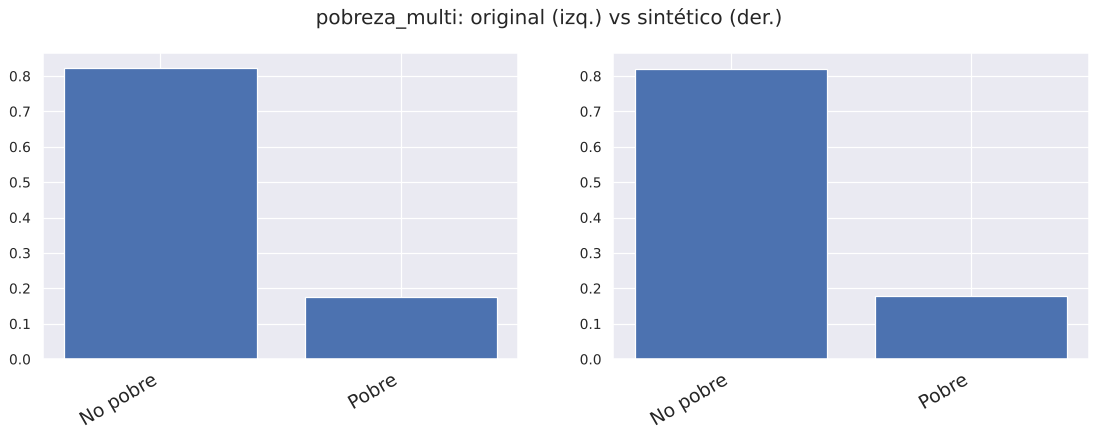

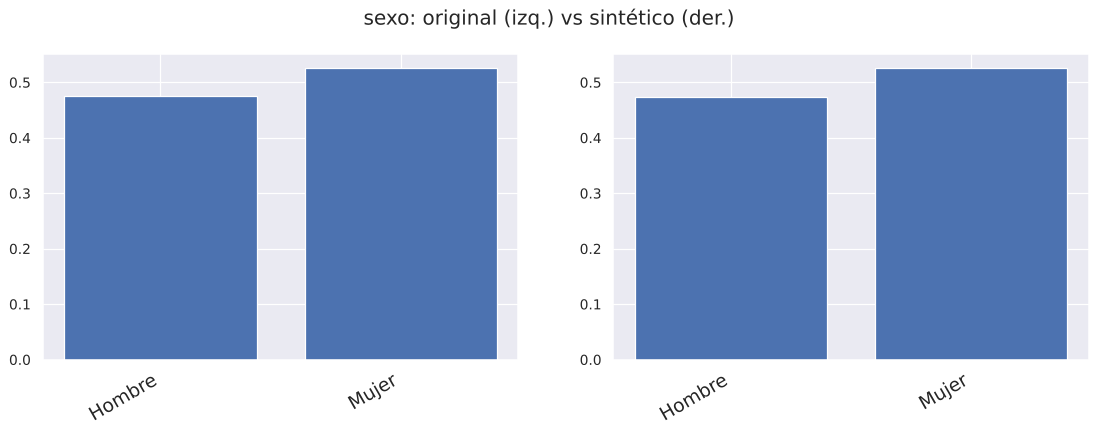

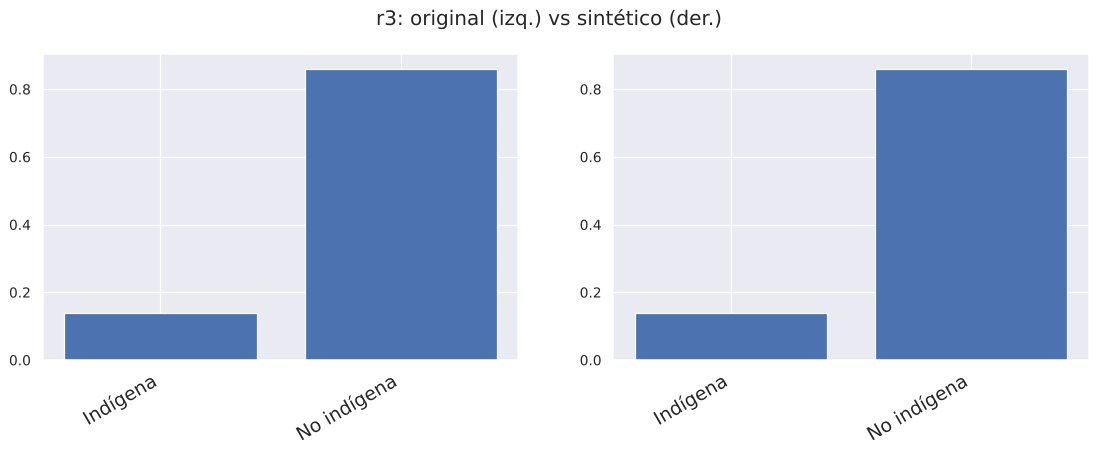

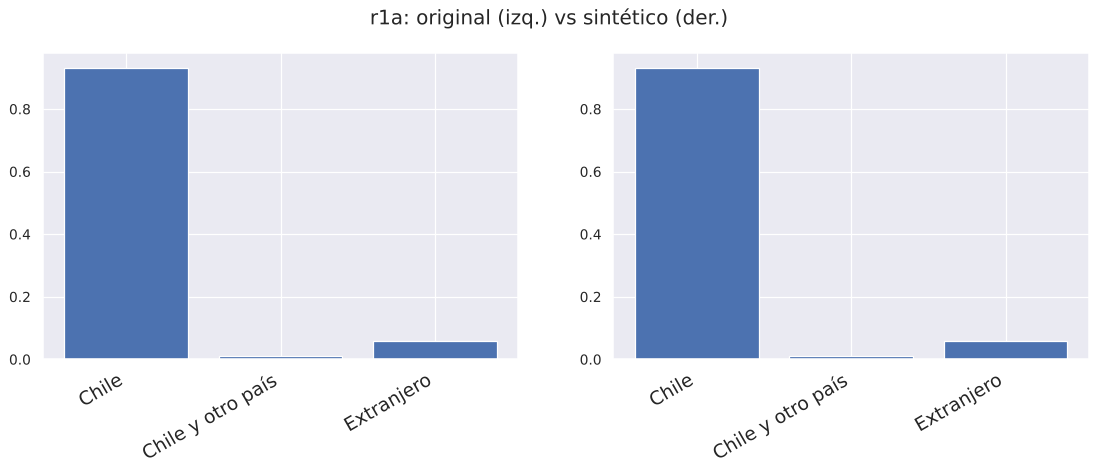

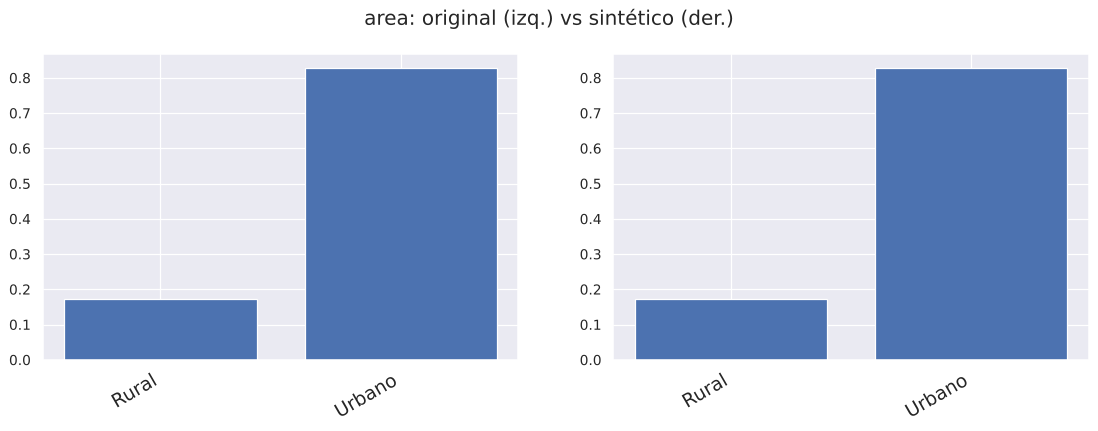

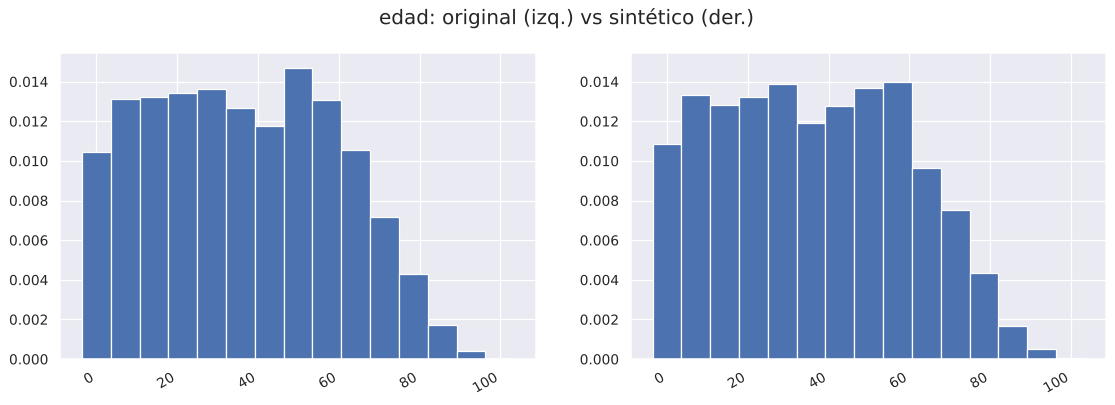

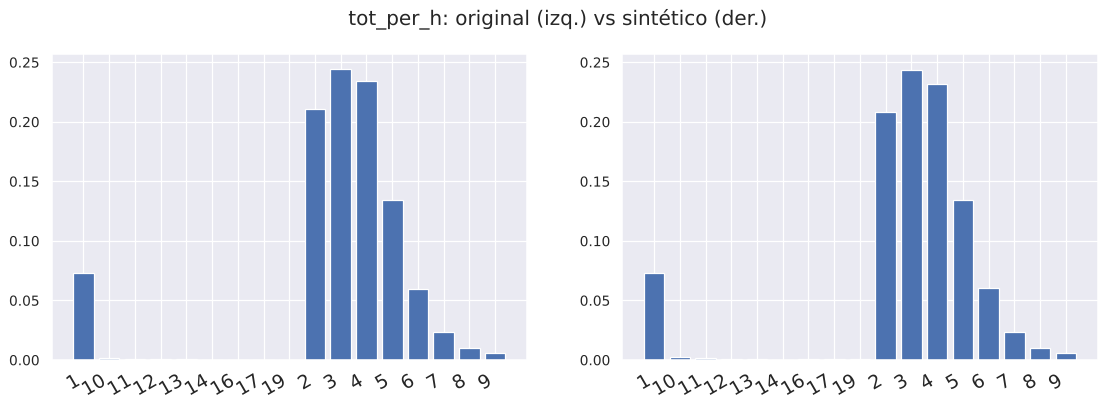

In [ ]:
# ModelInspector: compara cada variable del original (izquierda) con la del sintetico (derecha)
descripcion = read_json_file("descripcion_casen_dp.json")["attribute_description"]
inspector = ModelInspector(df_dp.copy(), sintetico.copy(), descripcion)

for variable in variables:
    inspector.compare_histograms(variable)
    plt.suptitle(f"{variable}: original (izq.) vs sintetico (der.)", fontsize=16)
    plt.show()

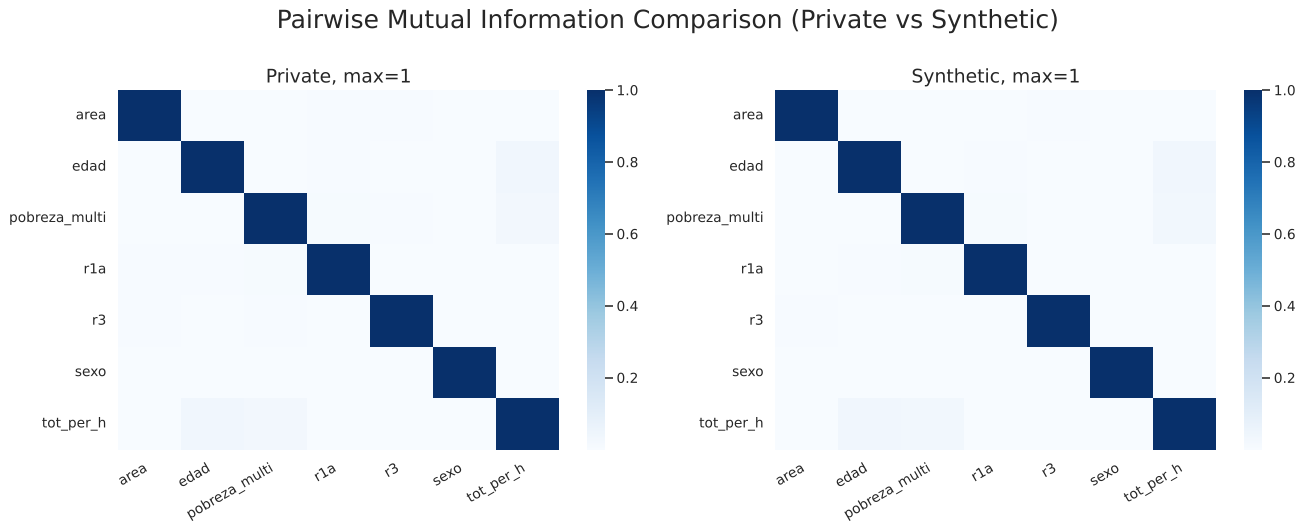

In [ ]:
# Informacion mutua entre pares de variables: ¿se mantienen las relaciones?
inspector.mutual_information_heatmap()
plt.show()

**Comentario de los resultados (pregunta 5)**

- **Las distribuciones de cada variable se mantienen casi iguales.** En los histogramas, el original (izquierda) y el sintetico (derecha) son practicamente identicos para pobreza, sexo, pueblo indigena, nacionalidad, zona y tamaño del hogar. La edad tiene diferencias pequeñas en la forma (por ejemplo, el peak entre 50 y 60 años se suaviza), porque DataSynthesizer la agrupa en tramos antes de agregar ruido.
- **El mapa de informacion mutua se ve casi igual en ambos lados**, pero hay que leerlo con cuidado. Casi todas las relaciones entre estas variables son debiles (colores muy claros), asi que el grafico no permite ver si se perdio una relacion especifica. Esa revision la hacemos con numeros en la pregunta 7.
- **Con ε = 1 y mas de 200 mil filas, el ruido agregado es pequeño** para las variables por separado. Con muchas filas, cada persona influye poco en los totales, asi que se necesita poco ruido para esconderla (Dwork & Roth, 2014).

Imagina que ahora cuentas con este mismo dataset con informacion mucho mas detallada, que podria contribuir a un proyecto desde la Ciencia de Datos con impacto social. Dependiendo del dataset que haya escogido su grupo, consideren el siguiente escenario:

- CIRI: el dataset incluye locaciones especificas, familias y detalles de investigacion sobre desapariciones y asesinatos, lo que podria contribuir a un proyecto de busqueda de victimas.

- Salud: el dataset incluye identificadores de pacientes, centro de salud de atencion y comuna de residencia, lo que podria contribuir a un proyecto de deteccion temprana o de acceso equitativo a tratamientos.

- CASEN: el dataset incluye la ubicacion exacta de cada hogar, su composicion familiar y el detalle de ingresos y beneficios recibidos, lo que podria contribuir a focalizar mejor la entrega de ayudas sociales.

En este caso podriamos preguntarnos, ¿que seria lo correcto? ¿anonimizar o mantener publica toda la informacion?

**`Pregunta (6)` Proceso de toma de decisiones: Frente a este dilema concreto ¿incluir todos los datos por precision y transparencia o aplicar tecnicas de privacidad para proteger a las personas y sus familias? ¿como lo resolverias? cuales son los pros y los contras de esta decision, en que tipo de contextos compartirias los datos reales y en cuales los datos sinteticos.**


**Respuesta pregunta 6**

**Nuestra decision: no publicar los datos completos. Proteger primero y dar acceso segun el uso.** La pregunta no es "todo publico o todo anonimo", sino **quien necesita que nivel de detalle y para que**.

**¿Por que no publicar todo?** En el escenario, la base tendria la ubicacion exacta de cada hogar, su composicion y sus ingresos y beneficios. Eso es un mapa de donde viven las familias mas vulnerables, quienes son migrantes o indigenas y que ayudas reciben. Publicado, podria usarse para discriminar (arriendos, empleos), para estafas dirigidas a quienes reciben bonos, para estigmatizar barrios o incluso para control migratorio. Ademas, la Ley 21.719 considera sensibles la situacion socioeconomica y el origen etnico, y exige anonimizar antes de publicar.

**¿Por que no anonimizar todo siempre?** Porque el escenario tiene un fin legitimo: **focalizar mejor las ayudas**. Para entregar un beneficio a un hogar, alguien tiene que saber donde esta ese hogar. Y, como vimos en nuestras pruebas, los datos sinteticos pueden perder informacion importante.

| | Datos reales (con acceso controlado) | Datos sinteticos / agregados (publicos) |
|---|---|---|
| **Pros** | Precision total; permiten entregar ayudas a hogares concretos; sirven para verificar resultados. | Protegen a las personas; se pueden compartir libremente; permiten que mas gente investigue y fiscalice. |
| **Contras** | Riesgo de filtraciones y de usos distintos al original; las personas pierden control sobre su informacion. | Pierden precision; pueden **borrar desigualdades** de grupos pequeños; no sirven para decisiones sobre un hogar especifico. |

Nuestras pruebas muestran ambos lados del dilema:

- **Riesgo real en los datos originales:** el 2,2 % de las personas es unica con solo 7 variables. Con la ubicacion exacta seria casi el 100 %.
- **Costo en precision segun ε** (tabla de abajo, muestra de 30.000 personas): con ε = 0,1 el sintetico muestra un 26,2 % de pobreza (el real es 17,5 %) y una brecha indigena *al reves*. Con ε = 1 y ε = 10 el total se parece mucho, pero **la brecha indigena (7,9 puntos en el original) casi desaparece** en todos los casos. Esto pasa porque la red bayesiana no conecto pueblo indigena con pobreza, asi que el problema no es solo el ruido.
- **Las filas sinteticas no son copias de personas.** Es normal que casi todas (96,7 %) coincidan con alguna persona real, porque con 7 variables hay pocas combinaciones posibles. El 2 % coincide con alguna combinacion que en el original era unica. Eso no significa que se haya filtrado a esa persona: el modelo no guarda filas reales, y la privacidad diferencial limita cuanto puede influir cada persona en lo que se genera (Ping et al., 2017).

**¿Donde compartiriamos cada tipo de dato?**

| Contexto | Que compartir |
|---|---|
| Entregar un beneficio a un hogar concreto (municipio, MDSF) | **Datos reales**, solo los necesarios, con base legal, registro de accesos y deber de secreto. |
| Investigacion academica que necesita precision (por ejemplo, evaluar un programa) | **Datos reales seudonimizados**, en un entorno seguro y con un acuerdo de uso (*Five Safes*). |
| Docencia, hackatones, prototipos de modelos, prensa | **Datos sinteticos con privacidad diferencial**, avisando que no sirven para conclusiones finas. |
| Informes publicos y activismo | **Cifras agregadas oficiales** (con supresion de grupos pequeños) y datos sinteticos para explorar. Las conclusiones importantes se verifican con los datos reales. |

En resumen, compartiriamos los datos reales solo cuando el beneficio para las propias personas lo justifique y existan controles. Para todo lo demas usariamos datos sinteticos o agregados, sabiendo sus limites.

In [ ]:
# Pregunta 6: ¿cuanto se pierde y cuanto se protege segun el nivel de privacidad (epsilon)?
# Para que corra rapido, usamos una muestra de 30.000 personas.
muestra = df_dp.sample(30_000, random_state=42)
muestra.to_csv("muestra_7_variables.csv", index=False)

def brecha_indigena(datos):
    tasa = datos.groupby("r3")["pobreza_multi"].apply(lambda s: (s == "Pobre").mean())
    return 100 * (tasa["Indigena"] - tasa["No indigena"])

resultados = [{"epsilon": "original", "% pobreza": round(100 * (muestra.pobreza_multi == "Pobre").mean(), 1),
               "brecha indigena (pp)": round(brecha_indigena(muestra), 1), "KL promedio": 0.0}]
for eps in [0.1, 1, 10]:
    d = DataDescriber(category_threshold=20)
    d.describe_dataset_in_correlated_attribute_mode("muestra_7_variables.csv", epsilon=eps, k=K,
                                                    attribute_to_is_categorical=es_categorica,
                                                    attribute_to_is_candidate_key=es_llave)
    d.save_dataset_description_to_file(f"desc_eps_{eps}.json")
    g = DataGenerator()
    g.generate_dataset_in_correlated_attribute_mode(len(muestra), f"desc_eps_{eps}.json")
    s = g.synthetic_dataset
    kl = np.mean([kl_test(muestra, s, v) for v in variables if es_categorica[v]])
    resultados.append({"epsilon": eps, "% pobreza": round(100 * (s.pobreza_multi == "Pobre").mean(), 1),
                       "brecha indigena (pp)": round(brecha_indigena(s), 1), "KL promedio": round(kl, 4)})

pd.DataFrame(resultados)

================ Constructing Bayesian Network (BN) ================
Adding ROOT tot_per_h
Adding attribute edad
Adding attribute r1a
Adding attribute pobreza_multi
Adding attribute sexo
Adding attribute r3
Adding attribute area
========================== BN constructed ==========================
================ Constructing Bayesian Network (BN) ================
Adding ROOT edad
Adding attribute tot_per_h
Adding attribute pobreza_multi
Adding attribute area
Adding attribute r1a
Adding attribute r3
Adding attribute sexo
========================== BN constructed ==========================
================ Constructing Bayesian Network (BN) ================
Adding ROOT pobreza_multi
Adding attribute tot_per_h
Adding attribute edad
Adding attribute area
Adding attribute r1a
Adding attribute sexo
Adding attribute r3
========================== BN constructed ==========================


,epsilon,% pobreza,brecha indígena (pp),KL promedio
0,original,17.5,7.9,0.0000
1,0.1,26.2,-9.3,0.3698
2,1,19.4,1.0,0.0223
3,10,17.3,0.5,0.0009


Revisamos tambien si el sintetico "copia" combinaciones de personas reales:

In [ ]:
# ¿El sintetico copia a personas reales con combinaciones unicas?
claves = list(map(tuple, df_dp[variables].astype(str).values))
unicas = {c for c, t in zip(claves, tam_grupo) if t == 1}

sint = sintetico.copy()
sint["edad"] = sint["edad"].round().astype(int)
claves_sint = list(map(tuple, sint[variables].astype(str).values))

todas = set(claves)
coincide_alguien = np.mean([c in todas for c in claves_sint])
coincide_unica = np.sum([c in unicas for c in claves_sint])
print(f"Filas sinteticas que coinciden con alguna persona real: {coincide_alguien:.1%}")
print(f"Filas sinteticas que coinciden con una persona de combinacion unica: {coincide_unica:,} "
      f"de {len(sint):,} ({coincide_unica / len(sint):.3%})")

Filas sintéticas que coinciden con alguna persona real: 96.7%
Filas sintéticas que coinciden con una persona de combinación única: 4,261 de 212,471 (2.005%)



### `6: Activismo de datos.`

**`Pregunta (7)` Reporte los resultados de la tecnica de anonimizacion (ModelInspector) y explique como se podria realizar activismo de datos con el conjunto anonimizado.**



**Respuesta pregunta 7**

**Resultados de ModelInspector.** Con ε = 1, el sintetico reproduce casi perfectamente cada variable por separado:

- La divergencia KL de las variables categoricas es practicamente 0 (0,004 para el tamaño del hogar).
- La diferencia maxima de la edad (prueba KS) es de 0,006.
- El porcentaje total de pobreza se mantiene.

**El problema aparece al mirar los grupos** (tabla y grafico de abajo):

-  **Migrantes:** la brecha se conserva. En el original, el 32,1 % de las personas extranjeras vive en pobreza multidimensional, contra un 16,8 % de las chilenas; en el sintetico, 32,3 % contra 17,0 %.
-  **Zona:** se conserva la brecha rural (21,5 % → 22,3 %) frente a la urbana (16,8 % → 17,0 %).
-  **Pueblos indigenas:** la brecha **casi desaparece**. En el original, el 23,8 % de las personas indigenas es pobre, contra un 16,6 % de las no indigenas (7 puntos de diferencia). En el sintetico queda en 18,8 % contra 17,8 %, solo 1 punto.

Esto pasa porque la red bayesiana conecto `r3` solo con la edad y la zona, no con la pobreza. El algoritmo prioriza las relaciones mas fuertes, y una relacion que afecta a un grupo del 14 % de la poblacion "pesa" poco. En una prueba adicional con k = 3 (no incluida en el notebook porque toma varios minutos mas), la brecha indigena se recupero solo en parte (21,3 % contra 17,6 %), pero a cambio la de migrantes se achico (24 % contra 17,5 %). Es decir, el resultado depende de que relaciones elige conservar el modelo.

**Leccion importante:** que ModelInspector diga que "las distribuciones se parecen" no significa que el dataset sirva para hablar de desigualdad. Un sintetico mal revisado podria usarse para afirmar que *los pueblos indigenas no son mas pobres que el resto*, lo que seria falso y dañino. Esto es lo que D'Ignazio y Klein (2020) advierten: los datos tambien pueden **invisibilizar** a quienes ya estan en desventaja.

**¿Como hacer activismo de datos con el conjunto anonimizado?** El activismo de datos es usar datos para visibilizar injusticias y presionar por cambios, muchas veces desde la sociedad civil y no desde el Estado (Milan & van der Velden, 2016). Con este dataset sintetico se podria:

1. **Visibilizar la pobreza migrante.** El grafico muestra que las personas extranjeras tienen casi el doble de pobreza multidimensional. Una organizacion de migrantes podria usarlo, sin exponer a nadie, para exigir mejor acceso a vivienda, salud y trabajo formal.
2. **Mostrar la brecha rural**, para pedir mas inversion en servicios fuera de las ciudades.
3. **Abrir los datos a mas personas.** Como el sintetico no tiene personas reales, se puede compartir con colegios, medios, juntas de vecinos u organizaciones sociales para que hagan sus propios analisis y preguntas, sin depender de que el Estado publique un informe.
4. **Usarlo con honestidad.** Cualquier campaña deberia indicar que los datos son sinteticos y **confirmar las cifras clave con los datos oficiales** antes de difundirlas. En nuestro caso, la brecha indigena tendria que tomarse de las cifras oficiales de la CASEN, no del sintetico.
5. **Pedir mejores datos.** El mismo hallazgo sirve como activismo: exigir que las instituciones, al publicar datos sinteticos, revisen que se mantengan las brechas de los grupos vulnerables y publiquen esa evaluacion. Asi la proteccion de la privacidad no termina borrando a esos grupos.

**Mejoras al dataset desde el activismo de datos:** incluir la opinion de las propias comunidades sobre que es ser pobre, mantener las preguntas de autoidentificacion, publicar con cada base sintetica una tabla de "brechas conservadas" y permitir que las organizaciones sociales propongan preguntas para la encuesta.

In [ ]:
# Pregunta 7: resultados de ModelInspector en numeros
metricas = []
for v in variables:
    if es_categorica[v]:
        metricas.append({"variable": v, "prueba": "KL (0 = identicas)", "valor": round(kl_test(df_dp, sintetico, v), 4)})
    else:
        metricas.append({"variable": v, "prueba": "KS (0 = identicas)", "valor": round(ks_test(df_dp, sintetico, v), 4)})
pd.DataFrame(metricas)

,variable,prueba,valor
0,pobreza_multi,KL (0 = idénticas),0.0000
1,sexo,KL (0 = idénticas),0.0000
2,r3,KL (0 = idénticas),0.0000
3,r1a,KL (0 = idénticas),0.0000
4,area,KL (0 = idénticas),0.0000
5,edad,KS (0 = idénticas),0.0056
6,tot_per_h,KL (0 = idénticas),0.0044


In [ ]:
# ¿El sintetico conserva las brechas de pobreza entre grupos? (lo que importa para el activismo)
def tasas(datos, var):
    return datos.groupby(var)["pobreza_multi"].apply(lambda s: 100 * (s == "Pobre").mean())

filas = []
for var in ["r3", "r1a", "area", "sexo"]:
    o, s = tasas(df_dp, var), tasas(sintetico, var)
    for g in o.index:
        filas.append({"variable": var, "grupo": g, "% pobreza original": round(o[g], 1),
                      "% pobreza sintetico": round(s.get(g, np.nan), 1)})
tabla_tasas = pd.DataFrame(filas)
tabla_tasas

,variable,grupo,% pobreza original,% pobreza sintético
0,r3,Indígena,23.8,18.8
1,r3,No indígena,16.6,17.8
2,r1a,Chile,16.8,17.0
3,r1a,Chile y otro país,16.7,19.5
4,r1a,Extranjero,32.1,32.3
5,area,Rural,21.5,22.3
6,area,Urbano,16.8,17.0
7,sexo,Hombre,17.5,18.1
8,sexo,Mujer,17.8,17.8


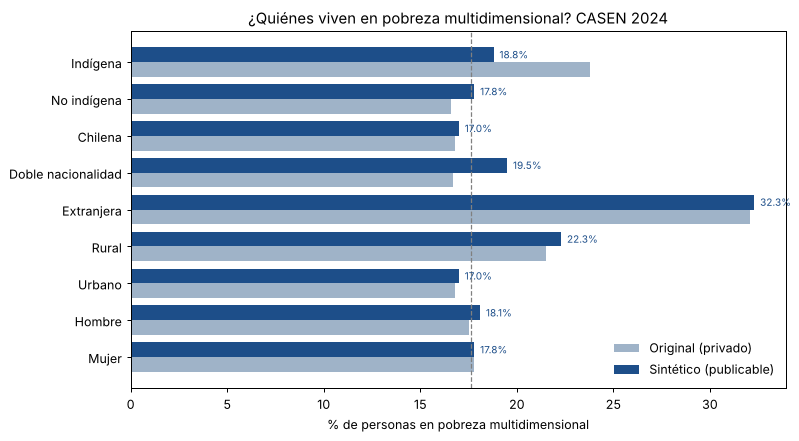

In [ ]:
# Visualizacion para activismo de datos
plt.style.use("default")
etiquetas = {"No indigena": "No indigena", "Indigena": "Indigena", "Chile": "Chilena",
             "Chile y otro pais": "Doble nacionalidad", "Extranjero": "Extranjera",
             "Urbano": "Urbano", "Rural": "Rural", "Hombre": "Hombre", "Mujer": "Mujer"}
t = tabla_tasas.copy()
t["etiqueta"] = t["grupo"].map(etiquetas)

fig, ax = plt.subplots(figsize=(9, 5))
y = np.arange(len(t))
ax.barh(y + 0.2, t["% pobreza original"], height=0.4, color="#9fb3c8", label="Original (privado)")
ax.barh(y - 0.2, t["% pobreza sintetico"], height=0.4, color="#1d4e89", label="Sintetico (publicable)")
ax.set_yticks(y)
ax.set_yticklabels(t["etiqueta"])
ax.invert_yaxis()
ax.axvline(100 * (df_dp.pobreza_multi == "Pobre").mean(), color="grey", ls="--", lw=1)
ax.set_xlabel("% de personas en pobreza multidimensional")
ax.set_title("¿Quienes viven en pobreza multidimensional? CASEN 2024")
ax.legend(loc="lower right", frameon=False)
for i, v in enumerate(t["% pobreza sintetico"]):
    ax.text(v + 0.3, i - 0.2, f"{v:.1f}%", va="center", fontsize=8, color="#1d4e89")
plt.tight_layout()
plt.show()

## Referencias

- AZ. (2026, 18 de noviembre). *Ley de Proteccion de Datos Personales: Congreso aprueba postergacion de su entrada en vigencia al 15 de octubre de 2027*. https://www.az.cl/ley-de-proteccion-de-datos-personales-congreso-aprueba-postergacion-de-su-entrada-en-vigencia-al-15-de-octubre-de-2027/
- Desai, T., Ritchie, F., & Welpton, R. (2016). *Five Safes: Designing data access for research* (Economics Working Paper Series 1601). University of the West of England.
- D'Ignazio, C., & Klein, L. F. (2020). *Data feminism*. MIT Press.
- Dwork, C., & Roth, A. (2014). The algorithmic foundations of differential privacy. *Foundations and Trends in Theoretical Computer Science, 9*(3–4), 211–407. https://doi.org/10.1561/0400000042
- Eguiguren Abogados. (2026, 17 de noviembre). *Ley 21.719: cuando entra en vigencia y si se posterga*. https://www.eguigurenyabogados.cl/newsletter/modificaciones-prorroga-regimen-ley-datos-personales
- Ley N° 17.374. (1970). Fija nuevo texto refundido, coordinado y actualizado del DFL N° 313 de 1960, que aprobara la Ley Organica Direccion Estadistica y Censos y crea el Instituto Nacional de Estadisticas. Biblioteca del Congreso Nacional de Chile.
- Ley N° 19.628. (1999). Sobre proteccion de la vida privada. Biblioteca del Congreso Nacional de Chile.
- Ley N° 20.285. (2008). Sobre acceso a la informacion publica. Biblioteca del Congreso Nacional de Chile.
- Ley N° 21.096. (2018). Consagra el derecho a proteccion de los datos personales. Biblioteca del Congreso Nacional de Chile.
- Ley N° 21.719. (2024). Regula la proteccion y el tratamiento de los datos personales y crea la Agencia de Proteccion de Datos Personales. *Diario Oficial de la Republica de Chile*, 13 de diciembre de 2024.
- Milan, S., & van der Velden, L. (2016). The alternative epistemologies of data activism. *Digital Culture & Society, 2*(2), 57–74. https://doi.org/10.14361/dcs-2016-0205
- Office of the United Nations High Commissioner for Human Rights. (2018). *A human rights-based approach to data: Leaving no one behind in the 2030 Agenda for Sustainable Development*. OHCHR.
- Ping, H., Stoyanovich, J., & Howe, B. (2017). DataSynthesizer: Privacy-preserving synthetic datasets. En *Proceedings of the 29th International Conference on Scientific and Statistical Database Management* (pp. 1–5). https://doi.org/10.1145/3085504.3091117
- Sweeney, L. (2002). k-anonymity: A model for protecting privacy. *International Journal of Uncertainty, Fuzziness and Knowledge-Based Systems, 10*(5), 557–570. https://doi.org/10.1142/S0218488502001648